#### Étape 1 : importer les bibliothèques

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#### Étape 2 : charger les données

In [37]:
df = pd.read_csv("ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


#### Étape 3 : vérifier la qualité des données

In [38]:
print("Dimensions        :", df.shape)
print("Valeurs manquantes:", df.isna().sum().sum())
print("Doublons          :", df.duplicated().sum())
print("Taux de pannes    : {:.2f} %".format(100 * df["Machine failure"].mean()))
df.describe()

Dimensions        : (10000, 14)
Valeurs manquantes: 0
Doublons          : 0
Taux de pannes    : 3.39 %


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


#### Étape 4 : visualiser le déséquilibre des classes

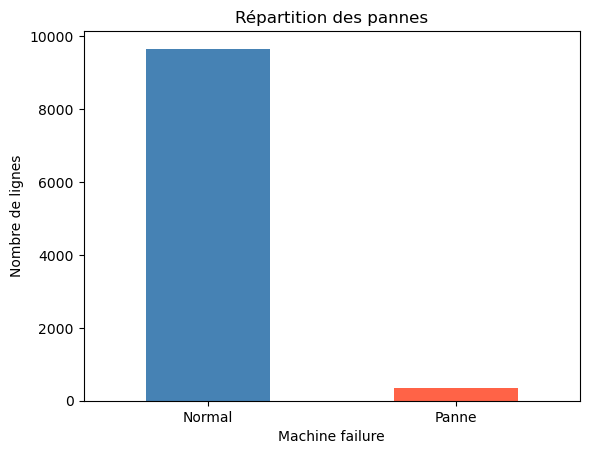

In [39]:
df["Machine failure"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.xticks([0, 1], ["Normal", "Panne"], rotation=0)
plt.title("Répartition des pannes")
plt.ylabel("Nombre de lignes")
plt.show()

#### Étape 5 : renommer les colonnes et convertir les températures

In [40]:
df = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "failure",
})

df["air_temp"] = df["air_temp"] - 273.15 # conversion d’unité (Kelvin vers °C)
df["process_temp"] = df["process_temp"] - 273.15
df.head()

,UDI,Product ID,Type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,24.95,35.45,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,25.05,35.55,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,24.95,35.35,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,25.05,35.45,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,25.05,35.55,1408,40.0,9,0,0,0,0,0,0


#### Étape 6 : créer de nouvelles variables

In [41]:
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power_w"] = df["torque"] * df["rpm"] * 2 * np.pi / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]

#### Étape 7 : encoder la colonne Type

In [42]:
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})
df["Type"].value_counts()

Type
0    6000
1    2997
2    1003
Name: count, dtype: int64

#### Étape 8: créer la cible multi-classes

In [43]:
# D'abord, regardez ce que contiennent les colonnes
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[modes].sum())
print("Pannes sans aucun mode :", ((df["failure"] == 1) & (df[modes].sum(axis=1) == 0)).sum())
print("Lignes avec plusieurs modes :", (df[modes].sum(axis=1) > 1).sum())

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64
Pannes sans aucun mode : 9
Lignes avec plusieurs modes : 24


In [44]:
def type_panne(row):
    if row["failure"] == 0:
        return "Normal"
    for mode in ["TWF", "HDF", "PWF", "OSF"]:
        if row[mode] == 1:
            return mode
    return "Autre"          # RNF (aléatoire) ou panne sans mode identifié

df["failure_type"] = df.apply(type_panne, axis=1)
print(df["failure_type"].value_counts())

failure_type
Normal    9661
HDF        115
PWF         91
OSF         78
TWF         46
Autre        9
Name: count, dtype: int64


#### Étape 9 : séparer variables (X) et cible (y)

In [45]:
y_bin = df["failure"]
y_multi = df["failure_type"]

df = df.drop(columns=["TWF", "HDF", "PWF", "OSF", "RNF", "UDI", "Product ID", "failure", "failure_type"])
X = df

X_train, X_test, yb_train, yb_test, ym_train, ym_test = train_test_split(
    X, y_bin, y_multi, test_size=0.2, stratify=y_multi, random_state=42
)

#### Étape 10 : séparer train et test

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train :", X_train.shape, "| pannes : {:.2f} %".format(100 * y_train.mean()))
print("Test  :", X_test.shape,  "| pannes : {:.2f} %".format(100 * y_test.mean()))

Train : (8000, 9) | pannes : 3.39 %
Test  : (2000, 9) | pannes : 3.40 %


#### Étape 11 : normaliser les variables

In [47]:
scaler = StandardScaler()
scaler.fit(X_train)                      # apprend moyenne et écart-type sur le TRAIN seulement

X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)
X_train_s.describe().loc[["mean", "std"]].round(2)

,Type,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power_w,wear_torque
mean,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


#### Étape 12 : sauvegarder les résultats

In [49]:
import os
os.makedirs("D:\master_ai\s1\projet_ml/data/processed", exist_ok=True)

X_train_s.assign(failure=y_train).to_csv("D:\master_ai\s1\projet_ml/data/processed/train.csv", index=False)
X_test_s.assign(failure=y_test).to_csv("D:\master_ai\s1\projet_ml/data/processed/test.csv", index=False)
joblib.dump(scaler, "D:\master_ai\s1\projet_ml/data/processed/scaler.pkl")
print("Fichiers sauvegardés")

Fichiers sauvegardés
